In [1]:
TEKSTBREEDTE = 108 / 25.4  # breedte van een afbeelding in het proefschrift (108 mm)
CORPS = 10           # lettergrootte van as-, legenda- en titeltekst (pt)
CORPS_KLEIN = 8.5    # lettergrootte van dichte labels en annotaties (pt)

# ── vaste kleuren per betekenis (gelijk in alle hoofdstukken) ─────────────
KLEUR_HOOFD = "#1A8259"                         # één reeks
KLEUR_VROEG, KLEUR_LAAT = "#A07FD8", "#1A8259"  # vroege / late periode
KLEUR_MIDDEN = "#E07B28"                        # tussenperiode (bij drie periodes)
KLEUR_DAG, KLEUR_NACHT = "#C98A3C", "#2A62A8"
KLEUR_MAN, KLEUR_VROUW = "#E100A3", "#3FB3CC"
KLEUR_WIJK = {1: "#2A62A8", 3: "#E07B28", 5: "#1BAF7A", 6: "#C2187F"}  # 5 = 5+11, 6 = 6+7



def komma_decimalen(fig):
    """Decimale komma in de standaard-asopmaak (ook kleurenschalen); eigen
    opmaak (FuncFormatter, vaste labels) blijft ongemoeid."""
    from matplotlib import ticker

    class Komma(ticker.Formatter):
        def __init__(self, basis):
            self.basis = basis
        def set_locs(self, locs):
            self.basis.set_locs(locs)
        def __call__(self, x, pos=None):
            return self.basis(x, pos).replace(".", ",")
        def get_offset(self):
            return self.basis.get_offset().replace(".", ",")

    for ax in fig.axes:
        for as_ in (ax.xaxis, ax.yaxis):
            for kies, zet in ((as_.get_major_formatter, as_.set_major_formatter),
                              (as_.get_minor_formatter, as_.set_minor_formatter)):
                f = kies()
                if isinstance(f, (ticker.ScalarFormatter, ticker.LogFormatter)):
                    f.axis = as_
                    zet(Komma(f))

def pas_breedte_aan(fig, doel=108 / 25.4, tight=None):
    """Maakt de figuur zo breed dat de opgeslagen afbeelding (ook met bbox 'tight')
    precies `doel` inch breed is. De letters blijven even groot; alleen het
    grafiekvlak wordt iets breder of smaller. Zet ook de decimalen op de assen
    om naar een komma."""
    import matplotlib as mpl
    komma_decimalen(fig)
    if tight is None:
        tight = mpl.rcParams["savefig.bbox"] == "tight"
    pad = mpl.rcParams["savefig.pad_inches"] if tight else 0
    oorspronkelijk = fig.get_figwidth()
    for _ in range(6):
        fig.canvas.draw()
        breedte = (fig.get_tightbbox().width if tight else fig.get_figwidth()) + 2 * pad
        if abs(breedte - doel) < 0.004:
            break
        nieuw = fig.get_figwidth() + (doel - breedte)
        if nieuw < 0.5 * doel:
            # een legende of label is op zich al breder dan het doel
            fig.set_figwidth(oorspronkelijk)
            print(f"Let op: figuur past niet binnen {doel * 25.4:.0f} mm; breedte niet aangepast.")
            break
        fig.set_figwidth(nieuw)

import os
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from shapely.geometry import box
from math import atan2, degrees
from matplotlib import patheffects as pe

os.environ["SHAPE_RESTORE_SHX"] = "YES"
pd.set_option("display.max_columns", 50)

SERIF = "Libertinus Serif"
if SERIF not in {f.name for f in font_manager.fontManager.ttflist}:
    print(f"{SERIF} niet gevonden; matplotlib valt terug op CMU Serif.")

mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": [SERIF, "CMU Serif", "DejaVu Serif"],
    "font.size": CORPS,
    "axes.titlesize": CORPS,
    "axes.labelsize": CORPS,
    "xtick.labelsize": CORPS,
    "ytick.labelsize": CORPS,
    "legend.fontsize": CORPS,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.bbox": "tight",
    "savefig.transparent": True,
    "savefig.dpi": 300,
})


def figsize(fractie=1.0, ratio=0.58):
    breedte = TEKSTBREEDTE * fractie
    return (breedte, breedte * ratio)

# ── eenvormige rasterlijnen in alle figuren ───────────────────────────────
import matplotlib as mpl
mpl.rcParams.update({
    "axes.grid": False,          # raster alleen waar het expliciet aangezet wordt
    "axes.axisbelow": True,      # raster achter de data
    "grid.color": "#96999B",
    "grid.linewidth": 0.4,
    "grid.alpha": 0.5,
    "grid.linestyle": "-",
})


In [2]:
GIS     = Path("../../data/algemeen/gis")
DB      = Path("../../data/algemeen/gebeurtenisdata_macro")
FIGUREN = Path("../../fig/H6")
FIGUREN.mkdir(parents=True, exist_ok=True)

STREETS_SHP      = GIS / "straten/1898_Street.shp"
STRAATZIJDEN_SHP = GIS / "straten/1898_straatzijden.shp"
WIJKEN_SHP       = GIS / "wijken/wijken_1886-1901.shp"
WIJKEN_IW_SHP    = GIS / "wijken/wijken_1921-1944.shp"

In [3]:
PERIOD_BOUNDS = {"vroeg": (1877, 1900), "interwar": (1919, 1939)}
DAGNACHT_MAP  = {"nacht": "nacht", "ochtendschemering": "nacht",
                 "avondschemering": "nacht", "dag": "dag"}

MIN_REGISTRATIES = 10

WIJKEN_MET_DATA     = ["1", "3", "5", "6"]
WIJKEN_ZONDER_DATA  = ["2", "4", "7", "8"]
WIJKEN_MET_DATA_IW  = ["3", "5", "6", "7", "11"]
WIJKEN_ZONDER_IW    = ["1", "2", "4", "8", "10", "12"]
WIJKEN_UITSLUITEN_IW = ["9"]

def assign_period(year):
    for label, (start, end) in PERIOD_BOUNDS.items():
        if start <= year <= end:
            return label
    return None

In [4]:
streets = gpd.read_file(STREETS_SHP)
if streets.crs is None:
    streets = streets.set_crs(epsg=31370)

COL_STREET_NAME = "SDEDGEO__1"
streets["straat"]      = streets[COL_STREET_NAME].astype(str).str.strip()
streets["segment_uid"] = streets["straat"] + "_" + streets.index.astype(str)

straatzijden_gdf = gpd.read_file(STRAATZIJDEN_SHP).to_crs(streets.crs)
wijken_gdf       = gpd.read_file(WIJKEN_SHP).to_crs(streets.crs)
wijken_iw_gdf    = gpd.read_file(WIJKEN_IW_SHP).to_crs(streets.crs)

wijken_gdf["SectionNr"]     = wijken_gdf["SectionNr"].astype(str).str.strip()
wijken_iw_gdf["Section_Nr"] = wijken_iw_gdf["Section_Nr"].astype(str).str.strip()

print(f"Segmenten: {len(streets)}, unieke straatnamen: {streets['straat'].nunique()}")

Segmenten: 1183, unieke straatnamen: 1176


In [5]:
centroids = streets[["segment_uid", "geometry"]].copy()
centroids["geometry"] = centroids.geometry.centroid

def wijk_per_segment(wijken, kolom):
    joined = gpd.sjoin(centroids, wijken[[kolom, "geometry"]], how="left", predicate="within")
    joined = joined.drop_duplicates(subset="segment_uid")
    return joined.set_index("segment_uid")[kolom]

segment_wijk    = wijk_per_segment(wijken_gdf, "SectionNr")
segment_wijk_iw = wijk_per_segment(wijken_iw_gdf, "Section_Nr")

streets["wijk"]    = streets["segment_uid"].map(segment_wijk)
streets["wijk_iw"] = streets["segment_uid"].map(segment_wijk_iw)

print(f"Zonder wijk (vroeg): {streets['wijk'].isna().sum()}")
print(f"Zonder wijk (interbellum): {streets['wijk_iw'].isna().sum()}")
print(streets["wijk"].value_counts().sort_index())

Zonder wijk (vroeg): 242
Zonder wijk (interbellum): 246
wijk
1    114
2    111
3     92
4     76
5    136
6    136
7     80
8    165
9     31
Name: count, dtype: int64


In [6]:
bestanden = sorted(p for p in DB.glob("*.xlsx") if not p.name.startswith("._"))
if not bestanden:
    raise FileNotFoundError(f"Geen xlsx-bestanden in {DB.resolve()}")

df_all = pd.concat(
    [pd.read_excel(p, engine="openpyxl").assign(source_file=p.name) for p in bestanden],
    ignore_index=True,
)

df_all["period"]   = df_all["E_YEAR"].apply(assign_period)
df_all["daynight"] = df_all["astro"].map(DAGNACHT_MAP)

print(f"Bestanden: {len(bestanden)}, records: {len(df_all)}")
print(df_all["period"].value_counts(dropna=False))

Bestanden: 197, records: 383125
period
interwar    211823
vroeg        90371
None         80931
Name: count, dtype: int64


In [7]:
naam_to_segment = (streets.sort_values("segment_uid")
                          .drop_duplicates(subset="straat")
                          .set_index("straat")["segment_uid"])

df = df_all.dropna(subset=["period", "daynight", "E_LOC_gis1898"]).copy()
df["straat"]      = df["E_LOC_gis1898"].astype(str).str.strip()
df["segment_uid"] = df["straat"].map(naam_to_segment)

n_ok = df["segment_uid"].notna().sum()
print(f"Na filters: {len(df)} records")
print(f"Gekoppeld: {n_ok} ({100 * n_ok / len(df):.1f}%)")
if n_ok < len(df):
    print("\nNiet gekoppeld:")
    print(df.loc[df["segment_uid"].isna(), "straat"].value_counts().head(10))

df = df.dropna(subset=["segment_uid"])
df["wijk"]    = df["segment_uid"].map(segment_wijk)
df["wijk_iw"] = df["segment_uid"].map(segment_wijk_iw)

Na filters: 122771 records
Gekoppeld: 122771 (100.0%)


In [8]:
BEBOUWING_1886_SHP = GIS / "bebouwing/bebouwing_1886.shp"
BEBOUWING_1908_SHP = GIS / "bebouwing/bebouwing_1908.shp"
WATER_1886_SHP     = GIS / "bebouwing/water_1886.shp"
WATER_1908_SHP     = GIS / "bebouwing/water_1908.shp"

bebouwing_1886 = gpd.read_file(BEBOUWING_1886_SHP).to_crs(streets.crs)
bebouwing_1908 = gpd.read_file(BEBOUWING_1908_SHP).to_crs(streets.crs)
water_1886     = gpd.read_file(WATER_1886_SHP).to_crs(streets.crs)
water_1908     = gpd.read_file(WATER_1908_SHP).to_crs(streets.crs)

print(f"Bebouwing 1886: {len(bebouwing_1886)}, 1908: {len(bebouwing_1908)}")
print(f"Water 1886: {len(water_1886)}, 1908: {len(water_1908)}")

Bebouwing 1886: 1745, 1908: 2090
Water 1886: 36, 1908: 37


In [9]:
import matplotlib.colors as mcolors
from mpl_toolkits.axes_grid1 import make_axes_locatable

WIJKEN_HOTSPOT    = ["1", "3", "5", "6"]
WIJKEN_HOTSPOT_IW = ["3", "5", "6", "7", "11"]

VMAX_GEM = 0.20
NORM_GEM = mcolors.PowerNorm(gamma=0.8, vmin=0, vmax=VMAX_GEM)
CMAP_HOT = "YlOrRd"

KLEUR_WATER         = "#c8d8e8"
KLEUR_BEBOUW_ZONDER = "#e8e8e8"
KLEUR_BEBOUW_MET    = "#c8c8c8"

def union(gdf):
    return gpd.GeoDataFrame(geometry=[gdf.union_all()], crs=gdf.crs)

def schaalbalk(ax, xmin, ymin, balk=500, hoogte=60):
    for i, kleur in enumerate(["black", "white"]):
        ax.fill_between([xmin + i*balk, xmin + (i+1)*balk],
                        [ymin, ymin], [ymin + hoogte, ymin + hoogte],
                        color=kleur, zorder=5)
    ax.fill_between([xmin, xmin + 2*balk], [ymin, ymin],
                    [ymin + hoogte, ymin + hoogte],
                    color="none", edgecolor="black", linewidth=0.8, zorder=6)
    for dx, label in [(0, "0"), (balk, "500 m"), (2*balk, "1 km")]:
        ax.text(xmin + dx, ymin - 100, label, ha="center", fontsize=CORPS_KLEIN, zorder=6)

def noordpijl(ax):
    ax.annotate("", xy=(0.05, 0.98), xycoords="axes fraction", xytext=(0.05, 0.93),
                arrowprops=dict(arrowstyle="-|>", color="black", lw=1.2), zorder=7)
    ax.text(0.05, 0.91, "N", transform=ax.transAxes,
            ha="center", va="top", fontsize=CORPS, zorder=7)

In [10]:
wijken_met    = wijken_gdf[wijken_gdf["SectionNr"].isin(WIJKEN_HOTSPOT)]
wijken_met_iw = wijken_iw_gdf[wijken_iw_gdf["Section_Nr"].isin(WIJKEN_HOTSPOT_IW)]

u_met    = union(wijken_met)
u_met_iw = union(wijken_met_iw)

bebouwing_met_data       = gpd.clip(bebouwing_1886, u_met)
bebouwing_zonder_data    = gpd.overlay(bebouwing_1886, u_met, how="difference")
bebouwing_met_data_iw    = gpd.clip(bebouwing_1908, u_met_iw)
bebouwing_zonder_data_iw = gpd.overlay(bebouwing_1908, u_met_iw, how="difference")

print(f"Bebouwing binnen analysewijken: {len(bebouwing_met_data)} vroeg, "
      f"{len(bebouwing_met_data_iw)} interbellum")

Bebouwing binnen analysewijken: 614 vroeg, 609 interbellum


In [11]:
def hotspot(periode, wijkkolom, wijken_selectie, clipzone):
    sel = df[(df["period"] == periode) & (df[wijkkolom].isin(wijken_selectie))]
    tab = (sel.groupby(["segment_uid", "daynight"]).size()
              .unstack(fill_value=0)
              .rename(columns={"dag": "n_dag", "nacht": "n_nacht"}))
    for k in ["n_dag", "n_nacht"]:
        if k not in tab:
            tab[k] = 0
    tab = tab.reset_index()

    gdf = gpd.clip(streets.merge(tab, on="segment_uid", how="inner"), clipzone)
    gdf["wijk_hotspot"] = gdf["segment_uid"].map(
        segment_wijk if wijkkolom == "wijk" else segment_wijk_iw)
    gdf = gdf[gdf["wijk_hotspot"].isin(wijken_selectie)].copy()

    totalen = gdf.groupby("wijk_hotspot")["n_nacht"].sum()
    gdf["n_nacht_wijk_aandeel"] = (gdf["n_nacht"] / gdf["wijk_hotspot"].map(totalen)).fillna(0)
    return gdf

hot_vroeg = hotspot("vroeg", "wijk", WIJKEN_HOTSPOT, u_met)
hot_iw    = hotspot("interwar", "wijk_iw", WIJKEN_HOTSPOT_IW, u_met_iw)

print(f"Segmenten: {len(hot_vroeg)} vroeg, {len(hot_iw)} interbellum")
print(f"Maximum aandeel: {hot_vroeg['n_nacht_wijk_aandeel'].max():.3f} vroeg, "
      f"{hot_iw['n_nacht_wijk_aandeel'].max():.3f} interbellum")
print(f"Boven vmax ({VMAX_GEM}): {(hot_vroeg['n_nacht_wijk_aandeel'] > VMAX_GEM).sum()} vroeg, "
      f"{(hot_iw['n_nacht_wijk_aandeel'] > VMAX_GEM).sum()} interbellum")

# aantallen voor de onderschriften van Afb. 6.15 en 6.16
nl = lambda x: f"{int(x):,}".replace(",", ".")
for naam, periode, kolom, wijken, h in [("6.15 (vroeg)", "vroeg", "wijk", WIJKEN_HOTSPOT, hot_vroeg),
                                       ("6.16 (interbellum)", "interwar", "wijk_iw", WIJKEN_HOTSPOT_IW, hot_iw)]:
    in_periode = df[df["period"] == periode]
    in_wijken = in_periode[in_periode[kolom].isin(wijken)]
    print(f"Afb. {naam}: {nl(len(in_periode))} registraties in de periode, "
          f"{nl(len(in_wijken))} in de getoonde wijken, "
          f"{nl((h['n_dag'] + h['n_nacht']).sum())} op de kaart "
          f"(waarvan {nl(h['n_nacht'].sum())} nachtelijk)")

Segmenten: 332 vroeg, 338 interbellum
Maximum aandeel: 0.179 vroeg, 0.205 interbellum
Boven vmax (0.2): 0 vroeg, 2 interbellum
Afb. 6.15 (vroeg): 30.867 registraties in de periode, 24.918 in de getoonde wijken, 24.918 op de kaart (waarvan 10.521 nachtelijk)
Afb. 6.16 (interbellum): 91.904 registraties in de periode, 79.848 in de getoonde wijken, 79.848 op de kaart (waarvan 26.644 nachtelijk)


In [12]:
MARGE = 250
XLIM = (min(hot_vroeg.total_bounds[0], hot_iw.total_bounds[0]) - MARGE,
        max(hot_vroeg.total_bounds[2], hot_iw.total_bounds[2]) + MARGE)
YLIM = (min(hot_vroeg.total_bounds[1], hot_iw.total_bounds[1]) - MARGE,
        max(hot_vroeg.total_bounds[3], hot_iw.total_bounds[3]) + MARGE)
RATIO_KAART = (YLIM[1] - YLIM[0]) / (XLIM[1] - XLIM[0])

print(f"Bereik: {XLIM[1]-XLIM[0]:.0f} x {YLIM[1]-YLIM[0]:.0f} m, verhouding {RATIO_KAART:.2f}")

Bereik: 4107 x 4547 m, verhouding 1.11


In [13]:
CBAR_RUIMTE = 0.55   # inches voor kleurenbalk en label

def hotspotkaart(hotspots, water, bebouwing_zonder, bebouwing_met, bestandsnaam):
    breedte = TEKSTBREEDTE
    fig = plt.figure(figsize=(breedte, breedte * RATIO_KAART + CBAR_RUIMTE))

    hoogte_kaart = (breedte * RATIO_KAART) / (breedte * RATIO_KAART + CBAR_RUIMTE)
    ax = fig.add_axes([0, 1 - hoogte_kaart, 1, hoogte_kaart])

    water.plot(ax=ax, color=KLEUR_WATER, linewidth=0, zorder=0)
    bebouwing_zonder.plot(ax=ax, color=KLEUR_BEBOUW_ZONDER, linewidth=0, zorder=1)
    bebouwing_met.plot(ax=ax, color=KLEUR_BEBOUW_MET, linewidth=0, zorder=1)

    hotspots.plot(column="n_nacht_wijk_aandeel", cmap=CMAP_HOT, linewidth=2.5,
                  norm=NORM_GEM, ax=ax, zorder=4, legend=False)

    schaalbalk(ax, XLIM[1] - 1400, YLIM[0] + 220)
    noordpijl(ax)

    ax.set_xlim(*XLIM)
    ax.set_ylim(*YLIM)
    ax.set_aspect("equal")
    ax.axis("off")

    cax = fig.add_axes([0.15, 0.055, 0.70, 0.015])
    sm = plt.cm.ScalarMappable(cmap=CMAP_HOT, norm=NORM_GEM)
    fig.colorbar(sm, cax=cax, orientation="horizontal",
                 label="Nachtaandeel binnen wijk")

    #fig.savefig(FIGUREN / f"{bestandsnaam}.pdf", bbox_inches=None)
    pas_breedte_aan(fig)
    fig.savefig(FIGUREN / f"{bestandsnaam}.png", bbox_inches=None)
    plt.show()

In [14]:
wijken_1886 = gpd.read_file(WIJKEN_SHP).to_crs(hot_vroeg.crs).rename(columns={"SectionNr": "wijk"})
wijken_1886 = wijken_1886[wijken_1886["wijk"].isin([1, 3, 5, 6])]

wijken_1921 = gpd.read_file(WIJKEN_IW_SHP).to_crs(hot_iw.crs).rename(columns={"Section_Nr": "wijk"})
wijken_1921["wijk"] = wijken_1921["wijk"].replace({11: 5, 7: 6})
wijken_1921 = wijken_1921[wijken_1921["wijk"].isin([3, 5, 6])].dissolve(by="wijk").reset_index()

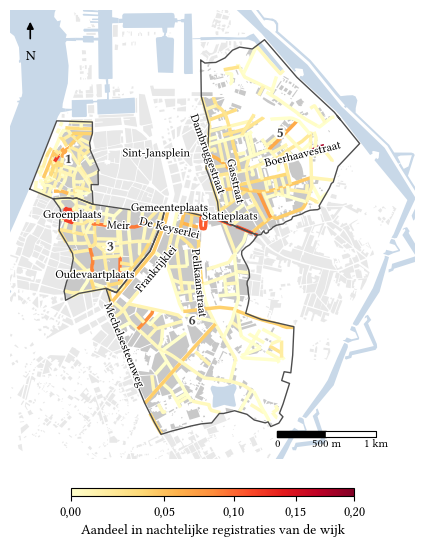

Geen wijkgrens voor wijk 2


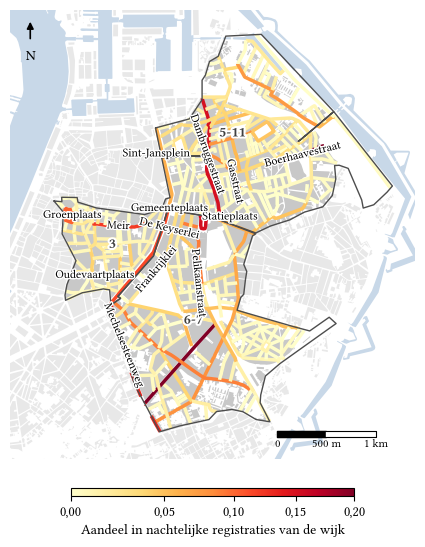

In [15]:
 
CBAR_RUIMTE = 0.55   # inches voor kleurenbalk en label

STRAATLABELS = {
    1: ("MEIR", "Meir"),
    2: ("GROENPLAATS", "Groenplaats"),
    3: ("OUDEVAARTPLAATS", "Oudevaartplaats"),
    4: ("KONINGIN ASTRIDPLEIN", "Statieplaats"),
    5: ("DE KEYSERLEI", "De Keyserlei"),
    6: ("FRANKLIN ROOSEVELTPLAATS", "Gemeenteplaats"),
    7: ("PELIKAANSTRAAT", "Pelikaanstraat"),
    8: ("FRANKRIJKLEI", "Frankrijklei"),
    9: ("MECHELSESTEENWEG", "Mechelsesteenweg"),
    10: ("BOERHAAVESTRAAT", "Boerhaavestraat"),
    11: ("SINT-JANSPLEIN", "Sint-Jansplein"),
    12: ("GASSTRAAT", "Gasstraat"),
    13: ("DAMBRUGGESTRAAT", "Dambruggestraat"),
}
PLEINEN = {"GROENPLAATS", "OUDEVAARTPLAATS", "KONINGIN ASTRIDPLEIN",
           "FRANKLIN ROOSEVELTPLAATS", "SINT-JANSPLEIN"}

LABEL_VERSCHUIVING = {3: (-260, -60), 4: (260, -10), 5: (-120, 30), 7: (0, -260),
                      8: (80, -120), 11: (-260, 0), 12: (0, -320), 13: (0, 170)}  # {nummer: (dx, dy)} in meter
HOEK = {}                              # {nummer: graden}, overschrijft berekende hoek

RAND_STRAAT = [pe.withStroke(linewidth=2, foreground="white")]
RAND_WIJK = [pe.withStroke(linewidth=3, foreground="white")]


# --- wijkgrenzen -------------------------------------------------------------

def als_nummer(reeks):
    return pd.to_numeric(reeks, errors="coerce").astype("Int64")


hot_vroeg["wijk"] = als_nummer(hot_vroeg["wijk"])
hot_iw["wijk"] = als_nummer(hot_iw["wijk"])

wijken_1886 = gpd.read_file(WIJKEN_SHP).to_crs(hot_vroeg.crs).rename(columns={"SectionNr": "wijk"})
wijken_1886["wijk"] = als_nummer(wijken_1886["wijk"])
wijken_1886 = wijken_1886[wijken_1886["wijk"].isin([1, 3, 5, 6])]

wijken_1921 = gpd.read_file(WIJKEN_IW_SHP).to_crs(hot_iw.crs).rename(columns={"Section_Nr": "wijk"})
wijken_1921["wijk"] = als_nummer(wijken_1921["wijk"]).replace({11: 5, 7: 6})
wijken_1921 = wijken_1921[wijken_1921["wijk"].isin([3, 5, 6])].dissolve(by="wijk").reset_index()


# --- labels ------------------------------------------------------------------

def straathoek(geometrie):
    lijn = max(getattr(geometrie, "geoms", [geometrie]), key=lambda g: g.length)
    (x0, y0), (x1, y1) = lijn.coords[0], lijn.coords[-1]
    hoek = degrees(atan2(y1 - y0, x1 - x0))
    return hoek - 180 if hoek > 90 else hoek + 180 if hoek < -90 else hoek


def labelposities(*kaartlagen, kolom="straat"):
    straten = pd.concat(kaartlagen)
    namen = straten[kolom].str.strip().str.upper()
    posities = {}
    for nr, (datanaam, _) in STRAATLABELS.items():
        segmenten = straten[namen == datanaam]
        if segmenten.empty:
            print(f"Niet gevonden: {datanaam}")
            continue
        geometrie = segmenten.geometry.union_all()
        punt = geometrie.representative_point()
        hoek = 0 if datanaam in PLEINEN else straathoek(geometrie)
        dx, dy = LABEL_VERSCHUIVING.get(nr, (0, 0))
        posities[nr] = (punt.x + dx, punt.y + dy, HOEK.get(nr, hoek))
    return posities


# --- kaart -------------------------------------------------------------------

def hotspotkaart(hotspots, water, bebouwing_zonder, bebouwing_met, wijkgrenzen,
                 bestandsnaam, straatlabels, wijkkolom="wijk", wijknamen={}):
    breedte = TEKSTBREEDTE
    fig = plt.figure(figsize=(breedte, breedte * RATIO_KAART + CBAR_RUIMTE))

    hoogte_kaart = (breedte * RATIO_KAART) / (breedte * RATIO_KAART + CBAR_RUIMTE)
    ax = fig.add_axes([0, 1 - hoogte_kaart, 1, hoogte_kaart])

    water.plot(ax=ax, color=KLEUR_WATER, linewidth=0, zorder=0)
    bebouwing_zonder.plot(ax=ax, color=KLEUR_BEBOUW_ZONDER, linewidth=0, zorder=1)
    bebouwing_met.plot(ax=ax, color=KLEUR_BEBOUW_MET, linewidth=0, zorder=1)

    wijkgrenzen.boundary.plot(ax=ax, color="0.3", linewidth=1.0,
                              joinstyle="round", capstyle="round", zorder=4.5)

    hotspots.plot(column="n_nacht_wijk_aandeel", cmap=CMAP_HOT, linewidth=2.5,
                  norm=NORM_GEM, ax=ax, zorder=4, legend=False)

    for wijk in hotspots[wijkkolom].dropna().unique():
        vlak = wijkgrenzen[wijkgrenzen[wijkkolom] == wijk]
        if vlak.empty:
            print(f"Geen wijkgrens voor wijk {wijk}")
            continue
        punt = vlak.geometry.union_all().representative_point()
        ax.text(punt.x, punt.y, str(wijknamen.get(wijk, wijk)), fontsize=CORPS,
                fontweight="bold", color="0.25", ha="center", va="center",
                zorder=5, path_effects=RAND_WIJK)

    for nr, (x, y, hoek) in straatlabels.items():
        ax.text(x, y, STRAATLABELS[nr][1], fontsize=CORPS_KLEIN, rotation=hoek,
                rotation_mode="anchor", ha="center", va="center",
                zorder=6, path_effects=RAND_STRAAT)

    schaalbalk(ax, XLIM[1] - 1400, YLIM[0] + 220)
    noordpijl(ax)

    ax.set_xlim(*XLIM)
    ax.set_ylim(*YLIM)
    ax.set_aspect("equal")
    ax.axis("off")

    cax = fig.add_axes([0.15, 0.055, 0.70, 0.015])
    sm = plt.cm.ScalarMappable(cmap=CMAP_HOT, norm=NORM_GEM)
    fig.colorbar(sm, cax=cax, orientation="horizontal",
                 label="Aandeel in nachtelijke registraties van de wijk")

    #fig.savefig(FIGUREN / f"{bestandsnaam}.pdf", bbox_inches=None)
    pas_breedte_aan(fig)
    fig.savefig(FIGUREN / f"{bestandsnaam}.png", bbox_inches=None)
    plt.show()


# --- tekenen -----------------------------------------------------------------

labels = labelposities(hot_vroeg, hot_iw)

hotspotkaart(hot_vroeg, water_1886, bebouwing_zonder_data, bebouwing_met_data,
             wijken_1886, "6.15_kaart_vroeg_nachthotspot", labels)

hotspotkaart(hot_iw, water_1908, bebouwing_zonder_data_iw, bebouwing_met_data_iw,
             wijken_1921, "6.16_kaart_interbellum_nachthotspot", labels,
             wijknamen={5: "5-11", 6: "6-7"})

In [16]:
from shapely.geometry import box
from matplotlib import patheffects
from matplotlib.transforms import ScaledTranslation

# verschuiving van straatnamen die elkaar overlappen, in punten (dx, dy)
VERSCHUIVING_PT = {"VAN ERTBORNSTRAAT": (-24, 6), "ANNEESSENSSTRAAT": (0, -8),
                   "QUELLINSTRAAT": (-24, 6), "APPELMANSSTRAAT": (14, -4)}


def closeup_straat(
    hoofdstraat,
    bestandsnaam,
    marge=100,
    periode="vroeg",
):
    # --------------------------------------------------------
    # Achtergrondlagen kiezen
    # --------------------------------------------------------

    if periode == "vroeg":
        water = water_1886
        bebouwing = bebouwing_1886
    elif periode == "interwar":
        water = water_1908
        bebouwing = bebouwing_1908
    else:
        raise ValueError("periode moet 'vroeg' of 'interwar' zijn")


    # --------------------------------------------------------
    # Hoofdstraat
    # --------------------------------------------------------

    hoofd = streets[
        streets["straat"].str.upper() == hoofdstraat.upper()
    ].copy()

    if hoofd.empty:
        raise ValueError(f"Straat niet gevonden: {hoofdstraat}")

    xmin, ymin, xmax, ymax = hoofd.total_bounds

    XLIM = (xmin - marge, xmax + marge)
    YLIM = (ymin - marge, ymax + marge)

    bbox = box(
        XLIM[0], YLIM[0],
        XLIM[1], YLIM[1]
    )


    # --------------------------------------------------------
    # Uitsnijden
    # --------------------------------------------------------

    straten_clip = gpd.clip(streets, bbox)
    water_clip = gpd.clip(water, bbox)
    bebouwing_clip = gpd.clip(bebouwing, bbox)
    hoofd_clip = gpd.clip(hoofd, bbox)


    # --------------------------------------------------------
    # Enkel aangrenzende straten bepalen
    # --------------------------------------------------------

    hoofd_geom = hoofd.geometry.unary_union

    # kleine buffer om minieme GIS-afwijkingen op te vangen
    aangrenzend = straten_clip[
        straten_clip.geometry.intersects(
            hoofd_geom.buffer(8)
        )
    ].copy()

    # hoofdstraat zelf niet dubbel meenemen
    aangrenzend = aangrenzend[
        aangrenzend["straat"].str.upper() != hoofdstraat.upper()
    ]


    # --------------------------------------------------------
    # Figuur
    # --------------------------------------------------------

    verhouding = (
        (YLIM[1] - YLIM[0]) /
        (XLIM[1] - XLIM[0])
    )

    fig, ax = plt.subplots(
        figsize=(
            TEKSTBREEDTE,
            TEKSTBREEDTE * verhouding
        )
    )
    fig.subplots_adjust(left=0, right=1, bottom=0, top=1)  # kaart over de volle breedte


    # --------------------------------------------------------
    # Achtergrond
    # --------------------------------------------------------

    water_clip.plot(
        ax=ax,
        color=KLEUR_WATER,
        linewidth=0,
        zorder=0,
    )

    bebouwing_clip.plot(
        ax=ax,
        color="#dedede",
        linewidth=0,
        zorder=1,
    )


    # --------------------------------------------------------
    # Alle straten
    # --------------------------------------------------------

    straten_clip.plot(
        ax=ax,
        color="#777777",
        linewidth=0.8,
        zorder=2,
    )


    # hoofdstraat iets duidelijker
    hoofd_clip.plot(
        ax=ax,
        color="#222222",
        linewidth=2.0,
        zorder=3,
    )


    # --------------------------------------------------------
    # Labels aangrenzende straten
    # --------------------------------------------------------

    for straatnaam, groep in aangrenzend.groupby("straat"):

        if (
            straatnaam is None
            or str(straatnaam).strip() == ""
            or str(straatnaam).lower() == "nan"
        ):
            continue

        geom = groep.loc[
            groep.geometry.length.idxmax(),
            "geometry"
        ]

        punt = geom.interpolate(
            0.5,
            normalized=True
        )

        dx, dy = VERSCHUIVING_PT.get(str(straatnaam).upper(), (0, 0))
        tekst = ax.text(
            punt.x,
            punt.y,
            straatnaam.title(),
            transform=ax.transData + ScaledTranslation(dx / 72, dy / 72, fig.dpi_scale_trans),
            fontsize=CORPS_KLEIN,
            ha="center",
            va="center",
            color="#222222",
            zorder=5,
        )

        tekst.set_path_effects([
            patheffects.withStroke(
                linewidth=2.5,
                foreground="white"
            )
        ])


    # --------------------------------------------------------
    # Hoofdstraat label
    # --------------------------------------------------------

    geom = hoofd_clip.loc[
        hoofd_clip.geometry.length.idxmax(),
        "geometry"
    ]

    punt = geom.interpolate(
        0.5,
        normalized=True
    )

    tekst = ax.text(
        punt.x,
        punt.y,
        hoofdstraat.title(),
        fontsize=CORPS,
        fontweight="bold",
        ha="center",
        va="center",
        color="#111111",
        zorder=6,
    )

    tekst.set_path_effects([
        patheffects.withStroke(
            linewidth=3,
            foreground="white"
        )
    ])


    # --------------------------------------------------------
    # Opmaak
    # --------------------------------------------------------

    ax.set_xlim(*XLIM)
    ax.set_ylim(*YLIM)

    ax.set_aspect("equal")
    ax.axis("off")

    pas_breedte_aan(fig, tight=True)
    fig.savefig(
        FIGUREN / f"{bestandsnaam}.png",
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()

/var/folders/m7/jhz7yh0x2rs_1grxt7m964600000gn/T/ipykernel_37309/2181393810.py:66: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  hoofd_geom = hoofd.geometry.unary_union
/var/folders/m7/jhz7yh0x2rs_1grxt7m964600000gn/T/ipykernel_37309/2181393810.py:103: UserWarning: The GeoDataFrame you are attempting to plot is empty. Nothing has been displayed.
  water_clip.plot(


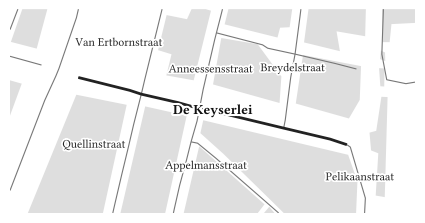

In [17]:
closeup_straat(
    hoofdstraat="DE KEYSERLEI",
    bestandsnaam="6.17_closeup_de_keyserlei",
    marge=80,
    periode="vroeg",
)

In [18]:
#closeup_straat(
#    hoofdstraat="GASSTRAAT",
#    bestandsnaam="closeup_gasstraat",
#    marge=80,
#    periode="vroeg",
#)